In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load the customer churn dataset

df = pd.read_csv("../dataset/customer_churn_dataset-testing-master.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,0


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 64374 entries, 0 to 64373
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   CustomerID         64374 non-null  int64
 1   Age                64374 non-null  int64
 2   Gender             64374 non-null  str  
 3   Tenure             64374 non-null  int64
 4   Usage Frequency    64374 non-null  int64
 5   Support Calls      64374 non-null  int64
 6   Payment Delay      64374 non-null  int64
 7   Subscription Type  64374 non-null  str  
 8   Contract Length    64374 non-null  str  
 9   Total Spend        64374 non-null  int64
 10  Last Interaction   64374 non-null  int64
 11  Churn              64374 non-null  int64
dtypes: int64(9), str(3)
memory usage: 5.9 MB


In [6]:
print("Number of records:", df.shape[0])
print("Number of features:", df.shape[1])

Number of records: 64374
Number of features: 12


In [7]:

numerical_features = df.select_dtypes(include=np.number).columns.tolist()
categorical_features = df.select_dtypes(include="object").columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['CustomerID', 'Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction', 'Churn']

Categorical features:
['Gender', 'Subscription Type', 'Contract Length']


C:\Users\HP\AppData\Local\Temp\ipykernel_5560\2828886353.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include="object").columns.tolist()


In [8]:
df.describe()

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000
mean,32187.500000,41.970982,31.994827,15.080234,5.400690,17.133952,541.023379,15.498850,0.473685
std,18583.317451,13.924911,17.098234,8.816470,3.114005,8.852211,260.874809,8.638436,0.499311
min,1.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,16094.250000,30.000000,18.000000,7.000000,3.000000,10.000000,313.000000,8.000000,0.000000
50%,32187.500000,42.000000,33.000000,15.000000,6.000000,19.000000,534.000000,15.000000,0.000000
75%,48280.750000,54.000000,47.000000,23.000000,8.000000,25.000000,768.000000,23.000000,1.000000
max,64374.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000,1.000000


In [9]:
df.describe(include="object")

C:\Users\HP\AppData\Local\Temp\ipykernel_5560\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,Gender,Subscription Type,Contract Length
count,64374,64374,64374
unique,2,3,3
top,Female,Standard,Monthly
freq,34353,21502,22130


In [10]:
print("Column name is in the dataset:")
for i, column in enumerate(df.columns, start=1):
    print(i, "-", column)

Column name is in the dataset:
1 - CustomerID
2 - Age
3 - Gender
4 - Tenure
5 - Usage Frequency
6 - Support Calls
7 - Payment Delay
8 - Subscription Type
9 - Contract Length
10 - Total Spend
11 - Last Interaction
12 - Churn


In [11]:
for column in df.columns:
    print(column, ":", df[column].nunique(), "unique values")

CustomerID : 64374 unique values
Age : 48 unique values
Gender : 2 unique values
Tenure : 60 unique values
Usage Frequency : 30 unique values
Support Calls : 11 unique values
Payment Delay : 31 unique values
Subscription Type : 3 unique values
Contract Length : 3 unique values
Total Spend : 901 unique values
Last Interaction : 30 unique values
Churn : 2 unique values


In [12]:
print(df.columns.tolist())

['CustomerID', 'Age', 'Gender', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Subscription Type', 'Contract Length', 'Total Spend', 'Last Interaction', 'Churn']


In [13]:
print(df["Churn"].value_counts())

Churn
0    33881
1    30493
Name: count, dtype: int64


In [14]:
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
0    52.631497
1    47.368503
Name: proportion, dtype: float64


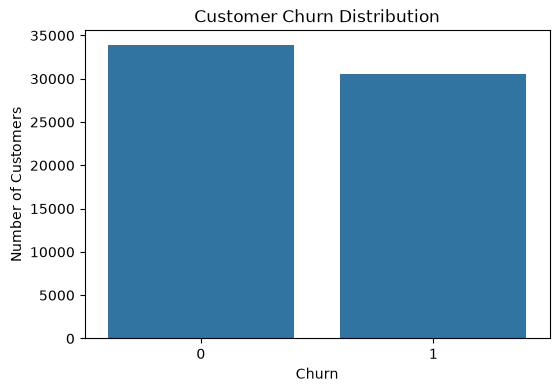

In [17]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_5560\599068136.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include="object").columns


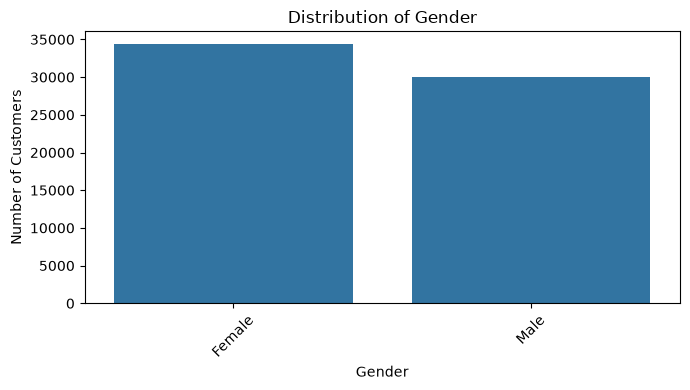

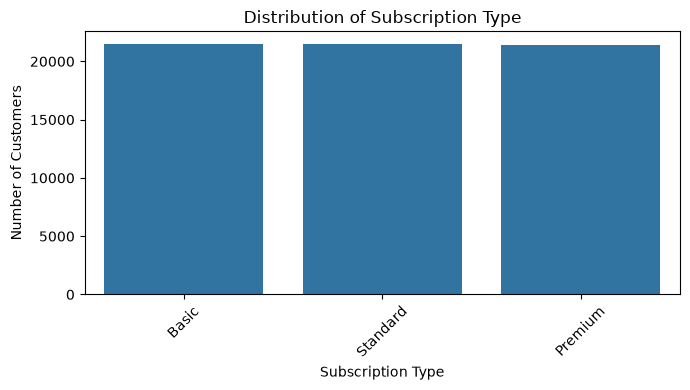

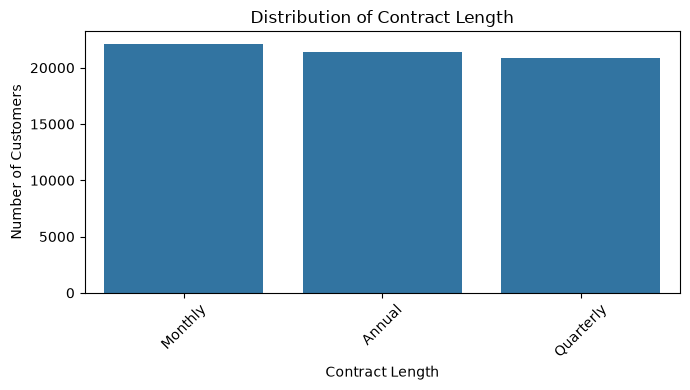

In [18]:
categorical_features = df.select_dtypes(include="object").columns

for column in categorical_features:
    # Skip high-cardinality columns such as customer IDs
    if df[column].nunique() <= 10:
        plt.figure(figsize=(7, 4))
        
        sns.countplot(data=df, x=column)
        
        plt.title(f"Distribution of {column}")
        plt.xlabel(column)
        plt.ylabel("Number of Customers")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

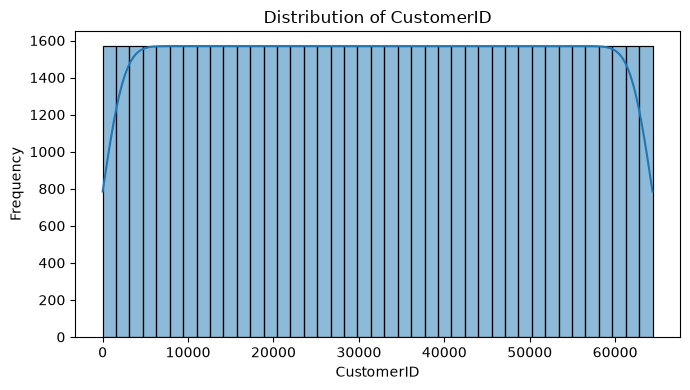

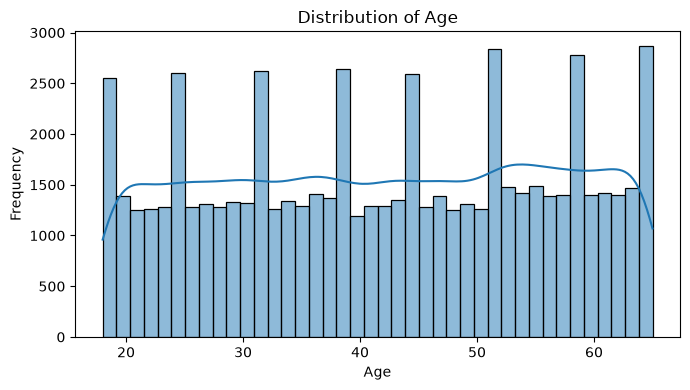

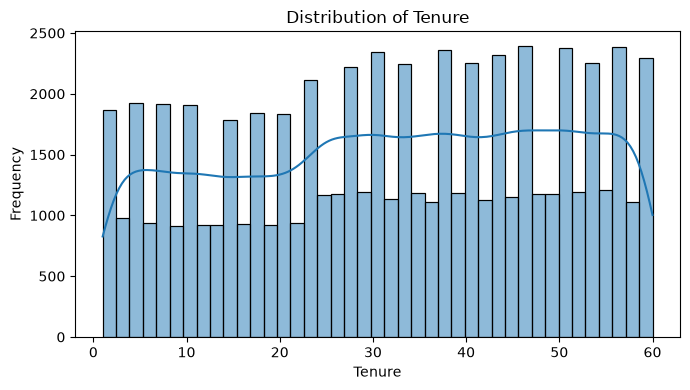

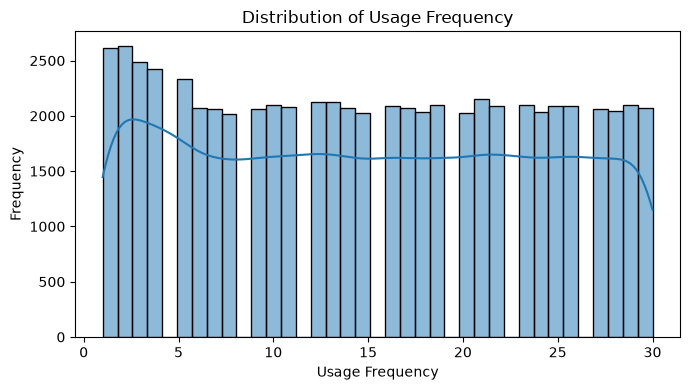

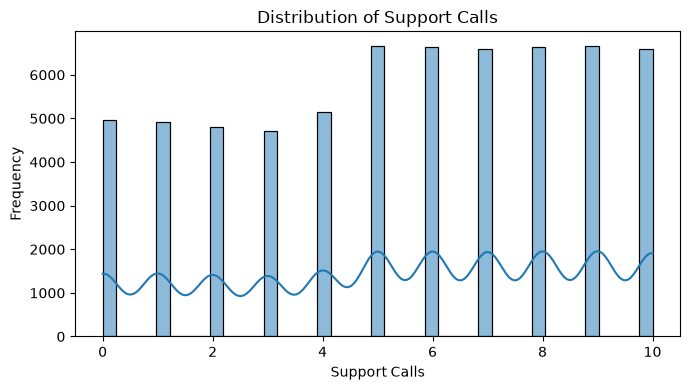

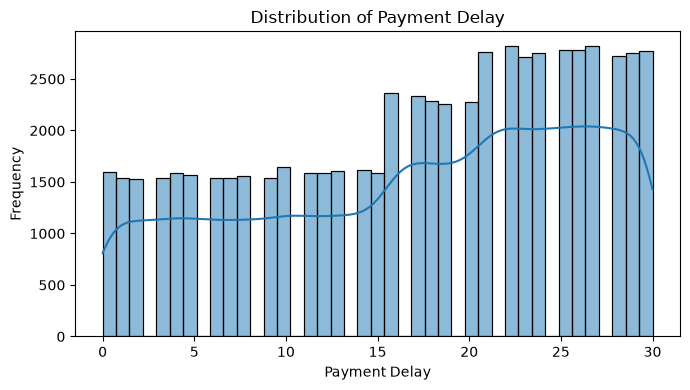

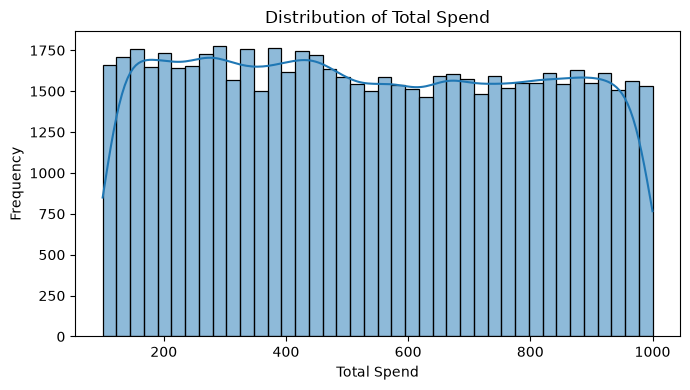

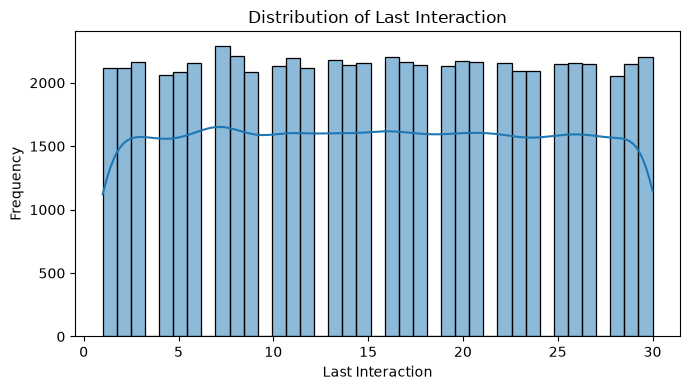

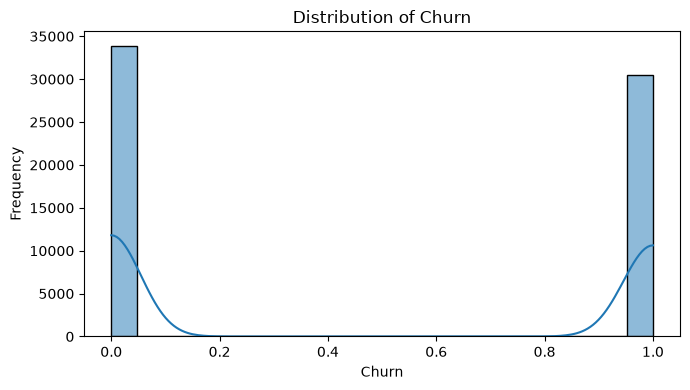

In [19]:
numerical_features = df.select_dtypes(include=np.number).columns

for column in numerical_features:
    plt.figure(figsize=(7, 4))
    
    sns.histplot(data=df, x=column, kde=True)
    
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

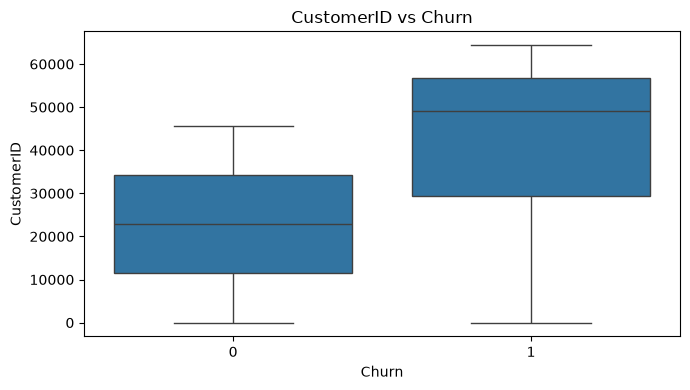

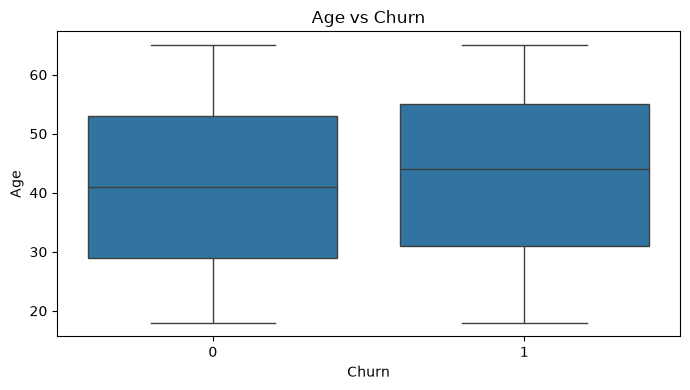

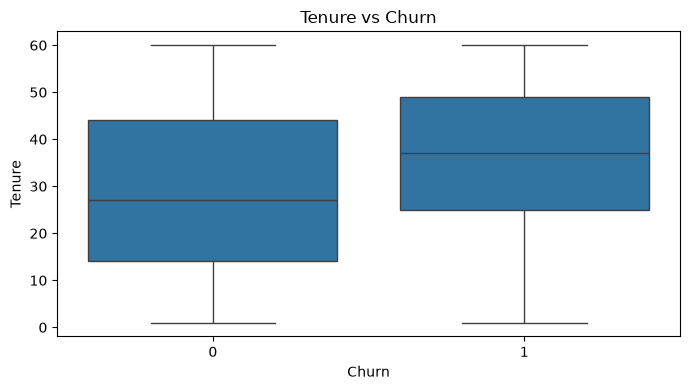

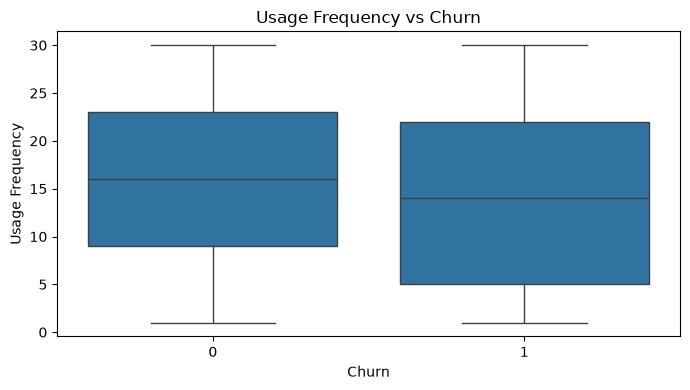

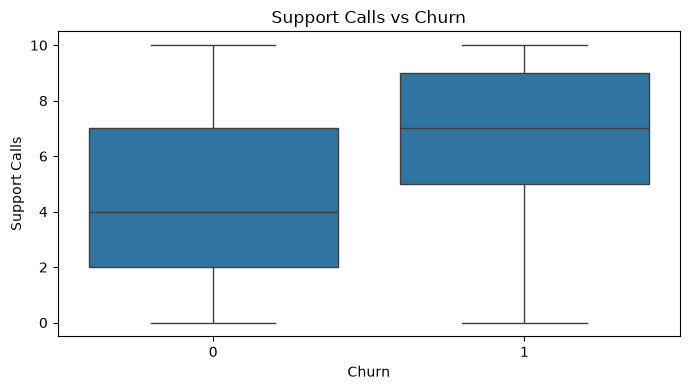

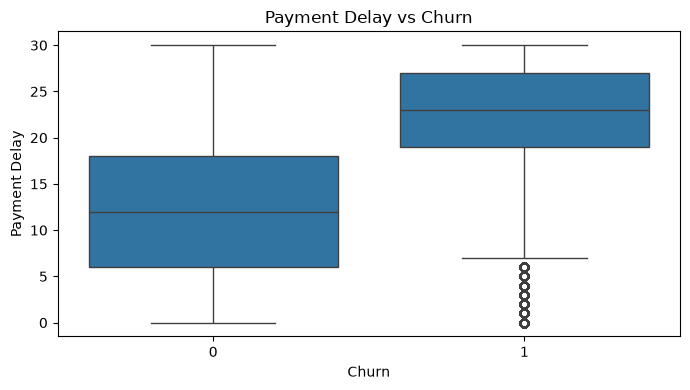

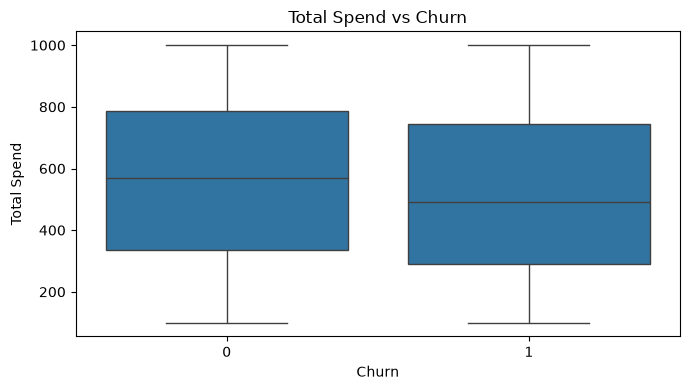

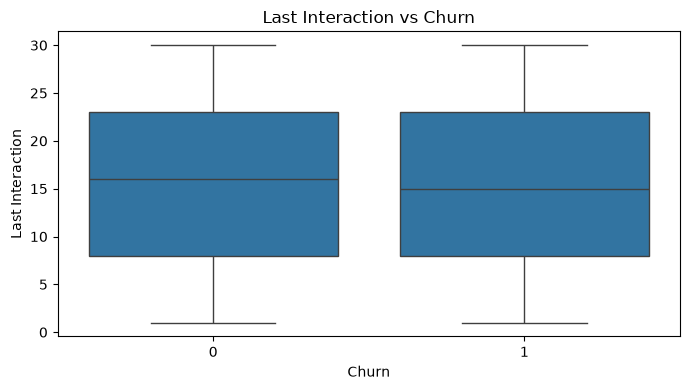

In [20]:
for column in numerical_features:
    if column != "Churn":
        plt.figure(figsize=(7, 4))
        
        sns.boxplot(data=df, x="Churn", y=column)
        
        plt.title(f"{column} vs Churn")
        plt.xlabel("Churn")
        plt.ylabel(column)
        plt.tight_layout()
        plt.show()

In [21]:
correlation_matrix = df[numerical_features].corr()

correlation_matrix

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
CustomerID,1.000000,0.043287,0.103296,-0.062699,0.164175,0.290684,-0.037068,-0.003718,0.529832
Age,0.043287,1.000000,-0.007763,-0.038331,0.005014,-0.016132,0.006490,-0.000148,0.063457
Tenure,0.103296,-0.007763,1.000000,0.023485,0.060065,0.055963,0.009474,0.005770,0.195327
Usage Frequency,-0.062699,-0.038331,0.023485,1.000000,-0.014072,0.031132,0.001527,-0.009192,-0.115098
Support Calls,0.164175,0.005014,0.060065,-0.014072,1.000000,0.064298,0.021750,0.001666,0.304631
Payment Delay,0.290684,-0.016132,0.055963,0.031132,0.064298,1.000000,-0.031119,-0.008076,0.557386
Total Spend,-0.037068,0.006490,0.009474,0.001527,0.021750,-0.031119,1.000000,-0.007692,-0.078867
Last Interaction,-0.003718,-0.000148,0.005770,-0.009192,0.001666,-0.008076,-0.007692,1.000000,-0.002818
Churn,0.529832,0.063457,0.195327,-0.115098,0.304631,0.557386,-0.078867,-0.002818,1.000000


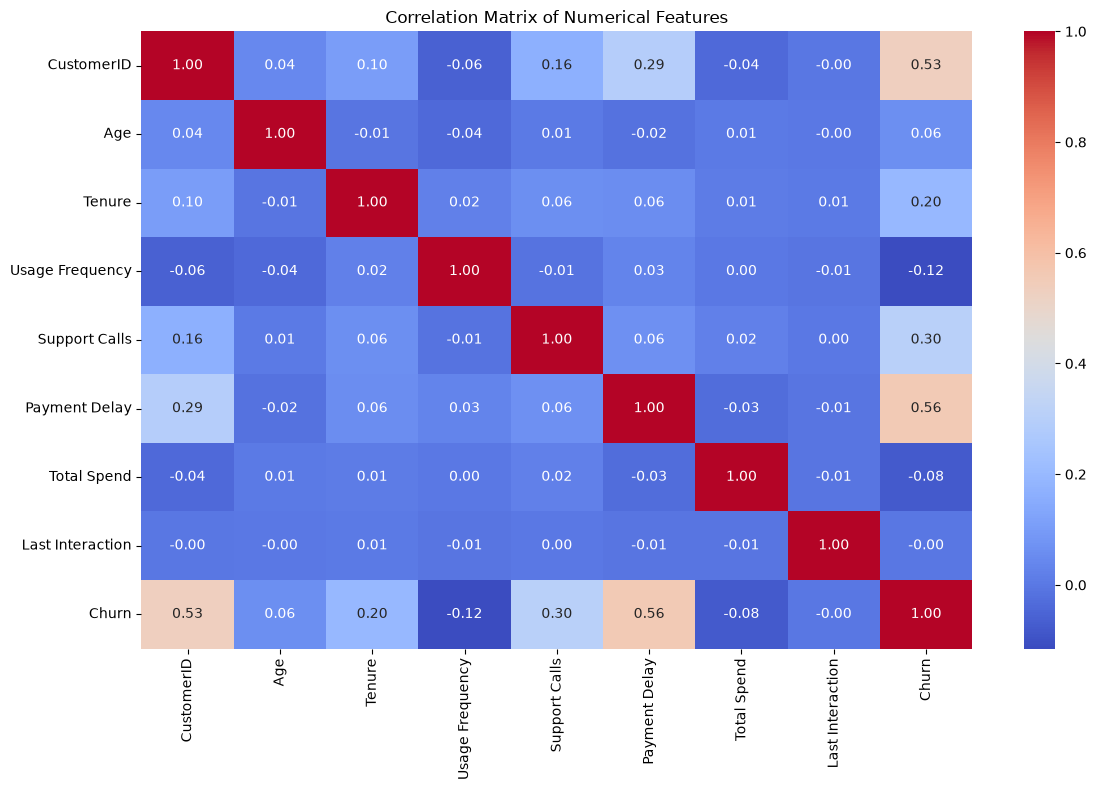

In [22]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

In [23]:
df.groupby("Churn")[numerical_features].mean()

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
Churn,,,,,,,,,
0,22846.794959,41.132700,28.826481,16.042915,4.500753,12.453086,560.541956,15.521944,0.0
1,42566.027121,42.902404,35.515200,14.010593,6.400617,22.334897,519.336143,15.473191,1.0


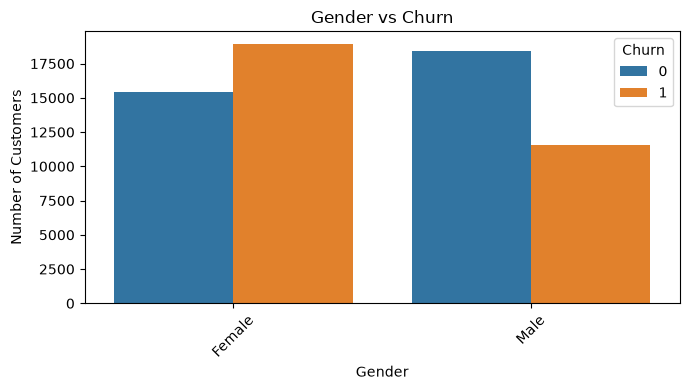

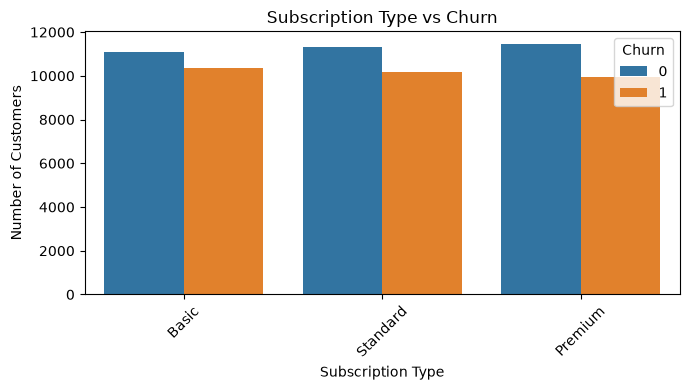

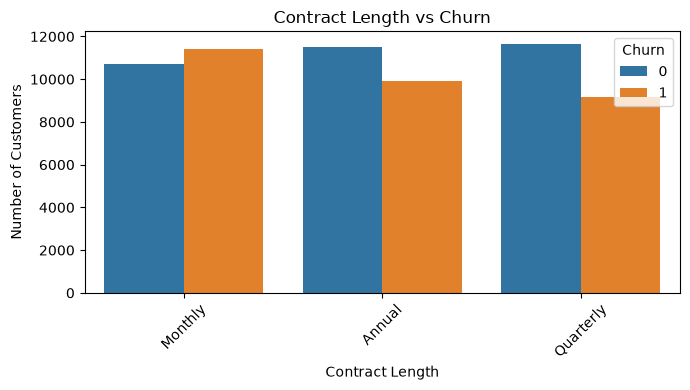

In [24]:
for column in categorical_features:
    if column != "Churn" and df[column].nunique() <= 10:
        
        plt.figure(figsize=(7, 4))
        
        sns.countplot(data=df, x=column, hue="Churn")
        
        plt.title(f"{column} vs Churn")
        plt.xlabel(column)
        plt.ylabel("Number of Customers")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

In [25]:
for column in categorical_features:
    if column != "Churn" and df[column].nunique() <= 10:
        
        churn_percentage = pd.crosstab(
            df[column],
            df["Churn"],
            normalize="index"
        ) * 100
        
        print("\n" + "=" * 60)
        print(f"Churn Percentage by {column}")
        print("=" * 60)
        
        print(churn_percentage.round(2))


Churn Percentage by Gender
Churn       0      1
Gender              
Female  44.95  55.05
Male    61.42  38.58

Churn Percentage by Subscription Type
Churn                  0      1
Subscription Type              
Basic              51.72  48.28
Premium            53.50  46.50
Standard           52.67  47.33

Churn Percentage by Contract Length
Churn                0      1
Contract Length              
Annual           53.78  46.22
Monthly          48.39  51.61
Quarterly        55.95  44.05


In [26]:
churn_encoded = df["Churn"].map({"No": 0, "Yes": 1})

numerical_churn_correlation = df[numerical_features].copy()
numerical_churn_correlation["Churn"] = churn_encoded

print("Correlation of numerical features with Churn:")
print(
    numerical_churn_correlation.corr()["Churn"]
    .sort_values(ascending=False)
)

Correlation of numerical features with Churn:
CustomerID         NaN
Age                NaN
Tenure             NaN
Usage Frequency    NaN
Support Calls      NaN
Payment Delay      NaN
Total Spend        NaN
Last Interaction   NaN
Churn              NaN
Name: Churn, dtype: float64


## EDA Observations and Inferences

### 1. Target Distribution
The distribution of the Churn target variable was analyzed to understand the proportion of customers who churned and those who did not.

### 2. Numerical Feature Distributions
The numerical features were visualized using histograms to understand their distributions, ranges, and possible unusual values.

### 3. Categorical Feature Distributions
Categorical features were analyzed using count plots to understand the distribution of customers across different categories.

### 4. Correlation Analysis
A correlation matrix and heatmap were used to examine relationships among numerical features and their relationship with the target.

### 5. Feature vs Churn Analysis
Numerical features were compared across churn classes using boxplots, while categorical features were analyzed using churn percentage tables and count plots.

### 6. Overall EDA Inference
The EDA provides an initial understanding of customer characteristics and patterns associated with churn. These findings will be considered during preprocessing, feature engineering, and model development.